# NYC Transit Optimization & Anomaly Challenge (MU-ICT, LHC)

Import Liberaries

In [7]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

Load the dataset

In [8]:
data_folder = Path("/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data")
taxi_files = sorted(data_folder.glob("yellow_tripdata_*.csv"))

taxi_previews = {}

for file in taxi_files:
    taxi_previews[file.name] = pd.read_csv(file, nrows=5_000)
    print("Loaded preview:", file.name)

Loaded preview: yellow_tripdata_2015-01.csv
Loaded preview: yellow_tripdata_2016-01.csv
Loaded preview: yellow_tripdata_2016-02.csv
Loaded preview: yellow_tripdata_2016-03.csv


Observation of dataset

In [9]:
for filename, preview in taxi_previews.items():
    print(filename)
    print("Preview shape:", preview.shape)
    print(preview.dtypes)
    print()

yellow_tripdata_2015-01.csv
Preview shape: (5000, 19)
VendorID                   int64
tpep_pickup_datetime      object
tpep_dropoff_datetime     object
passenger_count            int64
trip_distance            float64
pickup_longitude         float64
pickup_latitude          float64
RateCodeID                 int64
store_and_fwd_flag        object
dropoff_longitude        float64
dropoff_latitude         float64
payment_type               int64
fare_amount              float64
extra                    float64
mta_tax                  float64
tip_amount               float64
tolls_amount             float64
improvement_surcharge    float64
total_amount             float64
dtype: object

yellow_tripdata_2016-01.csv
Preview shape: (5000, 19)
VendorID                   int64
tpep_pickup_datetime      object
tpep_dropoff_datetime     object
passenger_count            int64
trip_distance            float64
pickup_longitude         float64
pickup_latitude          float64
RatecodeID         

Data processing

In [10]:
tables = []

for preview in taxi_previews.values():
    tables.append(preview.rename(columns={"RateCodeID": "RatecodeID"}))

trips = pd.concat(tables, ignore_index=True)

trips["tpep_pickup_datetime"] = pd.to_datetime(
    trips["tpep_pickup_datetime"], errors="coerce"
)
trips["tpep_dropoff_datetime"] = pd.to_datetime(
    trips["tpep_dropoff_datetime"], errors="coerce"
)

duration = trips["tpep_dropoff_datetime"] - trips["tpep_pickup_datetime"]
trips["duration_minutes"] = duration.dt.total_seconds() / 60

valid_trips = (trips["duration_minutes"] > 0) & (trips["trip_distance"] > 0)
clean_trips = trips.loc[valid_trips].copy()

print("Rows before preprocessing:", f"{len(trips):,}")
print("Rows after preprocessing:", f"{len(clean_trips):,}")
print("Rows excluded:", f"{len(trips) - len(clean_trips):,}")

Rows before preprocessing: 20,000
Rows after preprocessing: 19,880
Rows excluded: 120


Analyze the data

,trip_distance,duration_minutes
count,19880.00,19880.00
mean,2.94,14.30
std,3.49,50.52
min,0.01,0.02
25%,1.06,6.26
50%,1.78,10.07
75%,3.24,15.92
max,47.39,1438.77


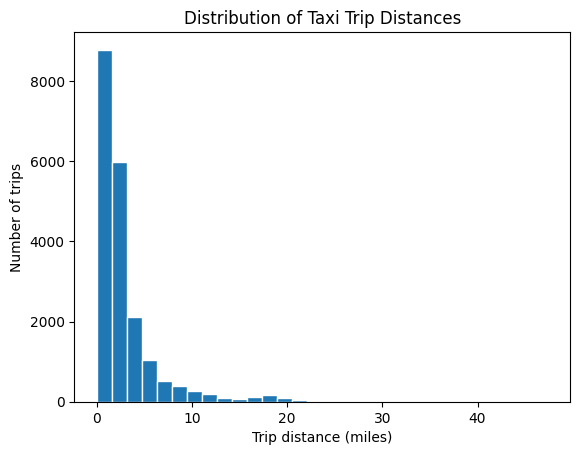

In [11]:
trip_summary = clean_trips[["trip_distance", "duration_minutes"]].describe()
display(trip_summary.round(2))

plt.hist(clean_trips["trip_distance"], bins=30, edgecolor="white")
plt.title("Distribution of Taxi Trip Distances")
plt.xlabel("Trip distance (miles)")
plt.ylabel("Number of trips")
plt.show()

5 longest trips

In [12]:
columns_to_show = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "trip_distance",
    "duration_minutes",
]

longest_trips = clean_trips.nlargest(5, "duration_minutes")
display(longest_trips[columns_to_show])

,tpep_pickup_datetime,tpep_dropoff_datetime,trip_distance,duration_minutes
4012,2015-01-13 18:37:53,2015-01-14 18:36:39,2.73,1438.766667
9130,2016-01-02 01:05:07,2016-01-03 01:02:11,1.71,1437.066667
11506,2016-02-19 20:52:39,2016-02-20 20:49:35,1.76,1436.933333
7273,2016-01-02 00:53:34,2016-01-03 00:50:23,2.74,1436.816667
7398,2016-01-02 00:54:24,2016-01-03 00:50:12,1.95,1435.800000


effect of unusually long durations

In [13]:
long_trips = clean_trips["duration_minutes"] > 120

print("Trips over 2 hours:", long_trips.sum())
print("Mean duration for all trips:", round(clean_trips["duration_minutes"].mean(), 2))
print(
    "Mean duration for trips of 2 hours or less:",
    round(clean_trips.loc[~long_trips, "duration_minutes"].mean(), 2)
)

Trips over 2 hours: 30
Mean duration for all trips: 14.3
Mean duration for trips of 2 hours or less: 12.47


**Pillar A – Classification (Surge Tier Prediction)**

*Pillar A (a) — Target Construction*

We create surge_tier using the rule from your report. A trip gets one point for a weekday peak-hour pickup, one for a distance of 2 miles or less, and one for a metered fare of at least $5 per mile. The final tiers are 0, 1, and 2, with scores of two or three both assigned to tier 2. These are the thresholds we chose for the analysis.

In [14]:
pillar_a = clean_trips.loc[clean_trips["fare_amount"] > 0].copy()

pickup = pillar_a["tpep_pickup_datetime"]
pillar_a["pickup_hour"] = pickup.dt.hour
pillar_a["pickup_day"] = pickup.dt.dayofweek  # Monday = 0, Sunday = 6

weekday = pillar_a["pickup_day"] < 5
morning_peak = pillar_a["pickup_hour"].between(7, 9)
evening_peak = pillar_a["pickup_hour"].between(16, 18)
weekday_peak = weekday & (morning_peak | evening_peak)

short_trip = pillar_a["trip_distance"] <= 2
fare_per_mile = pillar_a["fare_amount"] / pillar_a["trip_distance"]
high_fare_per_mile = fare_per_mile >= 5

score = (
    weekday_peak.astype(int)
    + short_trip.astype(int)
    + high_fare_per_mile.astype(int)
)

pillar_a["surge_tier"] = score.clip(upper=2)

tier_counts = pillar_a["surge_tier"].value_counts().reindex([0, 1, 2], fill_value=0)

print("Trips used:", len(pillar_a))
print("Trips excluded for missing or nonpositive fare:", len(clean_trips) - len(pillar_a))

display(pd.DataFrame({
    "Trip count": tier_counts,
    "Percentage": (tier_counts / len(pillar_a) * 100).round(2),
}))

Trips used: 19871
Trips excluded for missing or nonpositive fare: 9


,Trip count,Percentage
surge_tier,,
0,5272,26.53
1,4332,21.80
2,10267,51.67


*Pillar A (b) — Feature Preparation*

X contains the inputs and y contains the tier we want to predict. We’ll use pickup hour, day, location, and passenger count. Pickup hour and day are known at pickup, so we can use them even though they also help define the target. We leave completed-trip distance and fare out of X so the classifier can’t simply apply the full labeling rule.

We split the data into 80% for training and 20% for evaluation. stratify=y keeps the tier proportions similar in both sets.

In [15]:
from sklearn.model_selection import train_test_split

feature_columns = [
    "pickup_hour",
    "pickup_day",
    "pickup_longitude",
    "pickup_latitude",
    "passenger_count",
]

X = pillar_a[feature_columns]
y = pillar_a["surge_tier"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training trips:", len(X_train))
print("Held-out trips:", len(X_test))
display(X_train.head())

Training trips: 15896
Held-out trips: 3975


,pickup_hour,pickup_day,pickup_longitude,pickup_latitude,passenger_count
17176,7,3,-73.988419,40.738041,5
1466,21,5,-73.975891,40.748955,1
19189,7,3,-73.979553,40.786728,1
7715,0,5,-73.981552,40.758980,1
16656,7,3,-73.863892,40.769642,2


*Pillar A (c) — Model Development*

We’ll compare two models. The baseline always predicts the most common tier in the training data. The decision tree learns rules from the pickup features. We limit its depth to five so the first model stays easy to interpret

In [16]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

models = {
    "Majority-class baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(max_iter=1000),
    ),
    "Decision Tree": make_pipeline(
        SimpleImputer(strategy="median"),
        DecisionTreeClassifier(max_depth=5, random_state=42),
    ),
    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    ),
}

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
comparison = []

for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train,
        cv=folds, scoring=["accuracy", "f1_macro"]
    )

    comparison.append({
        "Model": name,
        "Mean accuracy": scores["test_accuracy"].mean(),
        "Mean macro F1": scores["test_f1_macro"].mean(),
    })

comparison = pd.DataFrame(comparison).sort_values(
    ["Mean macro F1", "Mean accuracy"], ascending=False
)

display(comparison.round(3))

best_model_name = comparison.loc[
    comparison["Model"] != "Majority-class baseline", "Model"
].iloc[0]

best_model = models[best_model_name]
best_model.fit(X_train, y_train)

print("Selected classifier:", best_model_name)

,Model,Mean accuracy,Mean macro F1
3,Random Forest,0.551,0.495
2,Decision Tree,0.589,0.490
1,Logistic Regression,0.516,0.259
0,Majority-class baseline,0.517,0.227


Selected classifier: Random Forest


*Pillar A (d) — Model Evaluation*

Accuracy tells us the fraction of correct predictions. Macro F1 gives all three tiers equal weight, so it helps us see whether performance goes beyond the most common tier. The confusion matrix shows which tiers the decision tree mixes up.

In [18]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

baseline = models["Majority-class baseline"]
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)
selected_predictions = best_model.predict(X_test)

results = pd.DataFrame({
    "Model": ["Majority-class baseline", best_model_name],
    "Accuracy": [
        accuracy_score(y_test, baseline_predictions),
        accuracy_score(y_test, selected_predictions),
    ],
    "Macro F1": [
        f1_score(y_test, baseline_predictions, average="macro", zero_division=0),
        f1_score(y_test, selected_predictions, average="macro", zero_division=0),
    ],
})

display(results.round(3))

matrix = confusion_matrix(y_test, selected_predictions, labels=[0, 1, 2])
display(pd.DataFrame(
    matrix,
    index=["Actual 0", "Actual 1", "Actual 2"],
    columns=["Predicted 0", "Predicted 1", "Predicted 2"],
))

,Model,Accuracy,Macro F1
0,Majority-class baseline,0.517,0.227
1,Random Forest,0.540,0.482


,Predicted 0,Predicted 1,Predicted 2
Actual 0,517,60,478
Actual 1,151,229,486
Actual 2,366,289,1399


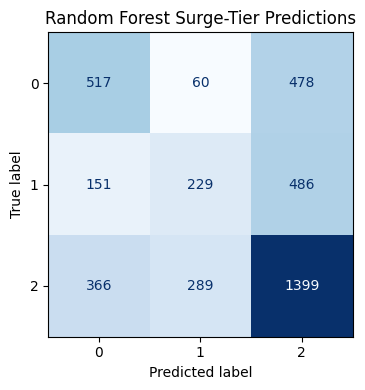

In [48]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    selected_predictions,
    labels=[0, 1, 2],
    cmap="Blues",
    colorbar=False,
    ax=ax,
)

ax.set_title("Random Forest Surge-Tier Predictions")
fig.tight_layout()
fig.savefig("/kaggle/working/pillar_a_confusion_matrix.png", dpi=200)
plt.show()

*Pillar A (e) — Prediction Generation*

Save one predicted tier per held-out trip. The row index lets you trace each prediction back to its record in the exploratory table.

In [19]:
predictions = pd.DataFrame({
    "exploratory_row_index": X_test.index,
    "predicted_surge_tier": selected_predictions,
})

predictions.to_csv("/kaggle/working/pillar_a_predictions.csv", index=False)

print("Model:", best_model_name)
print("Predictions saved:", len(predictions))

Model: Random Forest
Predictions saved: 3975


**Pillar B – Regression (CEPI Score Prediction)**

In [20]:
from pathlib import Path

import numpy as np
import pandas as pd

data_folder = Path("/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data")
taxi_files = sorted(data_folder.glob("yellow_tripdata_*.csv"))

tables = []
for file in taxi_files:
    trips = pd.read_csv(file, nrows=5_000)
    tables.append(trips.rename(columns={"RateCodeID": "RatecodeID"}))

pillar_b = pd.concat(tables, ignore_index=True)

pickup = pd.to_datetime(pillar_b["tpep_pickup_datetime"], errors="coerce")
dropoff = pd.to_datetime(pillar_b["tpep_dropoff_datetime"], errors="coerce")

pillar_b["tpep_pickup_datetime"] = pickup
pillar_b["duration_minutes"] = (dropoff - pickup).dt.total_seconds() / 60

valid = (pillar_b["duration_minutes"] > 0) & (pillar_b["trip_distance"] > 0)
pillar_b = pillar_b.loc[valid].copy()

print("Trips ready for Pillar B:", len(pillar_b))

Trips ready for Pillar B: 19880


*Pillar B (a) – Target Construction*

In [32]:
import numpy as np

# 1. Keep trips with usable coordinates in the study area.
valid_locations = (
    pillar_b["pickup_longitude"].between(-74.30, -73.65)
    & pillar_b["dropoff_longitude"].between(-74.30, -73.65)
    & pillar_b["pickup_latitude"].between(40.45, 40.95)
    & pillar_b["dropoff_latitude"].between(40.45, 40.95)
)

cepi_data = pillar_b.loc[
    valid_locations & (pillar_b["passenger_count"] >= 0)
].copy()

# 2. Estimate excess travel time for weekday peak pickups.
pickup = cepi_data["tpep_pickup_datetime"]
hour = pickup.dt.hour
weekday_peak = (pickup.dt.dayofweek < 5) & (
    hour.between(7, 9) | hour.between(16, 18)
)

reference_minutes = cepi_data["trip_distance"] / 20 * 60
excess_minutes = (cepi_data["duration_minutes"] - reference_minutes).clip(lower=0)
cepi_data["estimated_peak_delay_minutes"] = excess_minutes.where(weekday_peak, 0)

# 3. Assign pickup and drop-off locations to 0.01-degree grid cells.
grid_size = 0.01

pickup_x = np.floor((cepi_data["pickup_longitude"] + 74.30) / grid_size)
pickup_y = np.floor((cepi_data["pickup_latitude"] - 40.45) / grid_size)
dropoff_x = np.floor((cepi_data["dropoff_longitude"] + 74.30) / grid_size)
dropoff_y = np.floor((cepi_data["dropoff_latitude"] - 40.45) / grid_size)

cepi_data["zone_weight"] = (dropoff_x - pickup_x).abs() + (dropoff_y - pickup_y).abs()

# 4. Combine the components. log1p reduces the effect of extreme delays.
cepi_data["CEPI_Score"] = (
    cepi_data["passenger_count"]
    + np.log1p(cepi_data["estimated_peak_delay_minutes"])
    + cepi_data["zone_weight"]
)

print("Trips with a CEPI score:", len(cepi_data))
print("Trips excluded:", len(pillar_b) - len(cepi_data))
display(cepi_data["CEPI_Score"].describe().round(2))

Trips with a CEPI score: 19584
Trips excluded: 296


count    19584.00
mean         6.89
std          5.51
min          1.00
25%          3.56
50%          5.29
75%          8.15
max         48.00
Name: CEPI_Score, dtype: float64

*Pillar B (b) – Feature Preparation*

In [33]:
from sklearn.model_selection import train_test_split

pickup = cepi_data["tpep_pickup_datetime"]
cepi_data["pickup_hour"] = pickup.dt.hour
cepi_data["pickup_day"] = pickup.dt.dayofweek

features_b = [
    "pickup_hour",
    "pickup_day",
    "pickup_longitude",
    "pickup_latitude",
    "passenger_count",
]

X_b = cepi_data[features_b]
y_b = cepi_data["CEPI_Score"]

X_b_train, X_b_test, y_b_train, y_b_test = train_test_split(
    X_b, y_b, test_size=0.20, random_state=42
)

print("Training trips:", len(X_b_train))
print("Held-out trips:", len(X_b_test))

Training trips: 15667
Held-out trips: 3917


*Pillar B (c) – Model Development*

In [34]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.tree import DecisionTreeRegressor

models_b = {
    "Median baseline": DummyRegressor(strategy="median"),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, min_samples_leaf=5, random_state=42, n_jobs=-1
    ),
}

folds_b = KFold(n_splits=5, shuffle=True, random_state=42)
comparison_b = []

for name, model in models_b.items():
    scores = cross_val_score(
        model,
        X_b_train,
        y_b_train,
        cv=folds_b,
        scoring="neg_mean_absolute_error",
        error_score="raise",
    )
    comparison_b.append({"Model": name, "Mean MAE": -scores.mean()})

comparison_b = pd.DataFrame(comparison_b).sort_values("Mean MAE")
display(comparison_b.round(3))

best_model_b_name = comparison_b.iloc[0]["Model"]
best_model_b = models_b[best_model_b_name]
best_model_b.fit(X_b_train, y_b_train)

print("Selected model:", best_model_b_name)

,Model,Mean MAE
3,Random Forest,2.737
2,Decision Tree,2.737
1,Linear Regression,2.854
0,Median baseline,3.449


Selected model: Random Forest


In [35]:
display(comparison_b.round(8))

,Model,Mean MAE
3,Random Forest,2.737120
2,Decision Tree,2.737458
1,Linear Regression,2.854278
0,Median baseline,3.448543


*Pillar B (d) – Model Evaluation*

In [36]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

evaluation_b = []

for name in ["Median baseline", "Decision Tree", best_model_b_name]:
    model = models_b[name]
    model.fit(X_b_train, y_b_train)
    predicted_scores = model.predict(X_b_test)

    evaluation_b.append({
        "Model": name,
        "MAE": mean_absolute_error(y_b_test, predicted_scores),
        "RMSE": mean_squared_error(y_b_test, predicted_scores) ** 0.5,
    })

evaluation_b = pd.DataFrame(evaluation_b)
display(evaluation_b.round(4))

,Model,MAE,RMSE
0,Median baseline,3.2946,5.4479
1,Decision Tree,2.7283,4.1954
2,Random Forest,2.6823,4.1432


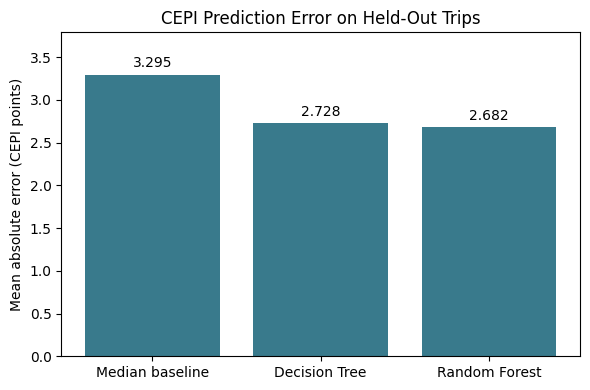

In [49]:
fig, ax = plt.subplots(figsize=(6, 4))

bars = ax.bar(evaluation_b["Model"], evaluation_b["MAE"], color="#397A8C")
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_ylim(0, evaluation_b["MAE"].max() * 1.15)
ax.set_ylabel("Mean absolute error (CEPI points)")
ax.set_title("CEPI Prediction Error on Held-Out Trips")

fig.tight_layout()
fig.savefig("/kaggle/working/pillar_b_heldout_mae.png", dpi=200)
plt.show()

*Pillar B (e) – Prediction*

In [38]:
cepi_predictions = pd.DataFrame({
    "exploratory_row_index": X_b_test.index,
    "predicted_CEPI_Score": best_model_b.predict(X_b_test),
})

cepi_predictions.to_csv(
    "/kaggle/working/pillar_b_predictions.csv",
    index=False,
)

print("Model:", best_model_b_name)
print("Predictions saved:", len(cepi_predictions))

Model: Random Forest
Predictions saved: 3917


**Pillar C – Unsupervised Learning (Ghost Corridor Identification)**

*Pillar C (a) – Zone Understanding*

In [39]:
# Start with the trips that passed the location checks in Pillar B.
pillar_c = cepi_data.copy()

# Give each pickup and drop-off grid cell a categorical ID.
for endpoint in ["pickup", "dropoff"]:
    x = np.floor(
        (pillar_c[f"{endpoint}_longitude"] + 74.30) / 0.01
    ).astype(int)
    y = np.floor(
        (pillar_c[f"{endpoint}_latitude"] - 40.45) / 0.01
    ).astype(int)

    pillar_c[f"{endpoint}_grid_zone"] = x.astype(str) + "_" + y.astype(str)

# Count trips for each directional corridor.
zone_columns = ["pickup_grid_zone", "dropoff_grid_zone"]

corridor_counts = (
    pillar_c.groupby(zone_columns)
    .size()
    .reset_index(name="trip_count")
    .sort_values("trip_count", ascending=False)
)

print("Trips used:", len(pillar_c))
print("Directional corridors:", len(corridor_counts))
display(corridor_counts.head())

Trips used: 19584
Directional corridors: 4304


,pickup_grid_zone,dropoff_grid_zone,trip_count
1037,30_30,32_30,116
1562,31_29,32_30,90
1671,31_30,32_30,86
2663,33_31,32_30,80
2188,32_30,31_29,80


*Pillar C (b) – Feature Engineering*

In [40]:
pickup = pillar_c["tpep_pickup_datetime"]
hour = pickup.dt.hour

pillar_c["weekday_peak"] = (pickup.dt.dayofweek < 5) & (
    hour.between(7, 9) | hour.between(16, 18)
)

pickup_frequency = pillar_c["pickup_grid_zone"].value_counts(normalize=True)
dropoff_frequency = pillar_c["dropoff_grid_zone"].value_counts(normalize=True)

corridor_features = pillar_c.groupby(zone_columns).agg(
    trip_count=("trip_distance", "size"),
    median_distance=("trip_distance", "median"),
    median_duration=("duration_minutes", "median"),
    peak_share=("weekday_peak", "mean"),
).reset_index()

corridor_features["pickup_frequency"] = (
    corridor_features["pickup_grid_zone"].map(pickup_frequency)
)
corridor_features["dropoff_frequency"] = (
    corridor_features["dropoff_grid_zone"].map(dropoff_frequency)
)

cluster_data = corridor_features.loc[corridor_features["trip_count"] >= 5].copy()

print("Corridors before filtering:", len(corridor_features))
print("Corridors retained:", len(cluster_data))
print("Trips represented by retained corridors:", cluster_data["trip_count"].sum())

display(cluster_data.sort_values("trip_count", ascending=False).head().round(3))

Corridors before filtering: 4304
Corridors retained: 901
Trips represented by retained corridors: 14543


,pickup_grid_zone,dropoff_grid_zone,trip_count,median_distance,median_duration,peak_share,pickup_frequency,dropoff_frequency
1037,30_30,32_30,116,1.270,8.375,0.672,0.048,0.072
1562,31_29,32_30,90,1.000,5.742,0.578,0.049,0.072
1671,31_30,32_30,86,0.900,6.425,0.349,0.043,0.072
2188,32_30,31_29,80,1.005,5.542,0.462,0.055,0.041
2663,33_31,32_30,80,1.020,6.400,0.738,0.035,0.072


*Pillar C (c) – Clustering*

In [41]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import StandardScaler

clustering_features = [
    "trip_count",
    "median_distance",
    "median_duration",
    "peak_share",
    "pickup_frequency",
    "dropoff_frequency",
]

scaler_c = StandardScaler()
X_c = scaler_c.fit_transform(cluster_data[clustering_features])

cluster_models = {}

for k in range(2, 7):
    model = MiniBatchKMeans(
        n_clusters=k,
        batch_size=256,
        n_init=10,
        random_state=42,
    )
    model.fit(X_c)
    cluster_models[k] = model
    print(f"K = {k}: fitted {len(model.cluster_centers_)} cluster centers")

K = 2: fitted 2 cluster centers
K = 3: fitted 3 cluster centers
K = 4: fitted 4 cluster centers
K = 5: fitted 5 cluster centers
K = 6: fitted 6 cluster centers


*Pillar C (d) – Cluster Evaluation*

In [42]:
from sklearn.metrics import silhouette_score

cluster_results = []

for k, model in cluster_models.items():
    labels = model.predict(X_c)
    sizes = pd.Series(labels).value_counts()

    cluster_results.append({
        "K": k,
        "Silhouette score": silhouette_score(X_c, labels),
        "Smallest cluster": sizes.min(),
        "Largest cluster": sizes.max(),
    })

cluster_results = pd.DataFrame(cluster_results)
display(cluster_results.round(3))

,K,Silhouette score,Smallest cluster,Largest cluster
0,2,0.183,365,536
1,3,0.220,185,503
2,4,0.240,94,351
3,5,0.251,27,292
4,6,0.248,17,344


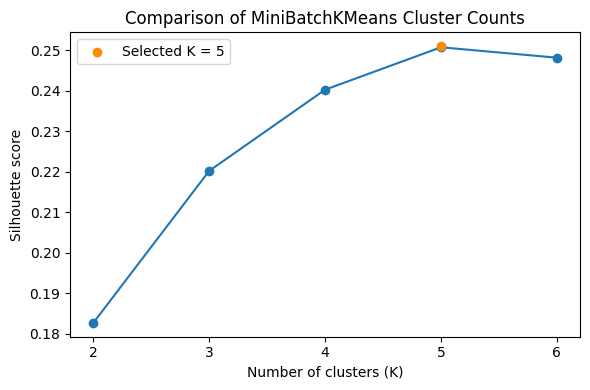

In [50]:
fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(cluster_results["K"], cluster_results["Silhouette score"], marker="o")
ax.scatter(5, 0.251, color="darkorange", zorder=3, label="Selected K = 5")
ax.set_xticks(cluster_results["K"])
ax.set_xlabel("Number of clusters (K)")
ax.set_ylabel("Silhouette score")
ax.set_title("Comparison of MiniBatchKMeans Cluster Counts")
ax.legend()

fig.tight_layout()
fig.savefig("/kaggle/working/pillar_c_silhouette.png", dpi=200)
plt.show()

*Pillar C (d) – Inspect the five cluster profiles*

In [43]:
selected_cluster_model = cluster_models[5]
cluster_data["cluster"] = selected_cluster_model.predict(X_c)

cluster_profiles = cluster_data.groupby("cluster").agg(
    corridors=("trip_count", "size"),
    total_trips=("trip_count", "sum"),
    typical_trips_per_corridor=("trip_count", "median"),
    typical_distance_miles=("median_distance", "median"),
    typical_duration_minutes=("median_duration", "median"),
    typical_peak_share=("peak_share", "median"),
    typical_pickup_frequency=("pickup_frequency", "median"),
    typical_dropoff_frequency=("dropoff_frequency", "median"),
)

display(cluster_profiles.round(3))

,corridors,total_trips,typical_trips_per_corridor,typical_distance_miles,typical_duration_minutes,typical_peak_share,typical_pickup_frequency,typical_dropoff_frequency
cluster,,,,,,,,
0,292,3151,9.0,2.69,13.325,0.182,0.041,0.014
1,259,2745,9.0,1.28,6.967,0.375,0.014,0.018
2,164,6577,36.5,1.05,6.550,0.327,0.041,0.032
3,27,189,6.0,17.15,33.800,0.364,0.014,0.032
4,159,1881,10.0,2.80,14.433,0.600,0.018,0.039


*Pillar C (e) – Corridor Identification*

In [44]:
# Get each corridor's distance to all five cluster centers.
distances = selected_cluster_model.transform(X_c)
labels = cluster_data["cluster"].to_numpy()

# Keep only the distance to the corridor's assigned center.
cluster_data["distance_to_center"] = distances[np.arange(len(cluster_data)), labels]

# Calculate a separate cutoff for each cluster.
cutoff = cluster_data.groupby("cluster")["distance_to_center"].transform(
    lambda values: values.quantile(0.95)
)

ghost_corridors = cluster_data.loc[
    cluster_data["distance_to_center"] >= cutoff
].sort_values("distance_to_center", ascending=False)

print("Candidate ghost corridors:", len(ghost_corridors))
print("Candidates per cluster:")
print(ghost_corridors["cluster"].value_counts().sort_index())

display(ghost_corridors[[
    "pickup_grid_zone",
    "dropoff_grid_zone",
    "cluster",
    "trip_count",
    "median_distance",
    "median_duration",
    "peak_share",
    "distance_to_center",
]].head(5).round(3))

ghost_corridors.to_csv("/kaggle/working/pillar_c_ghost_corridors.csv", index=False)

Candidate ghost corridors: 47
Candidates per cluster:
cluster
0    15
1    13
2     9
3     2
4     8
Name: count, dtype: int64


,pickup_grid_zone,dropoff_grid_zone,cluster,trip_count,median_distance,median_duration,peak_share,distance_to_center
1037,30_30,32_30,2,116,1.270,8.375,0.672,6.210
2261,32_30,43_32,3,6,11.175,24.200,1.000,4.632
1562,31_29,32_30,2,90,1.000,5.742,0.578,4.596
2663,33_31,32_30,2,80,1.020,6.400,0.738,4.253
1671,31_30,32_30,2,86,0.900,6.425,0.349,4.215


**1. Integration of Outputs of All Three Pillars**

In [45]:
a_predictions = pd.read_csv("/kaggle/working/pillar_a_predictions.csv")
b_predictions = pd.read_csv("/kaggle/working/pillar_b_predictions.csv")

trip_id = "exploratory_row_index"
corridor_keys = ["pickup_grid_zone", "dropoff_grid_zone"]

# Keep trips with a held-out prediction from both models.
combined = a_predictions.merge(
    b_predictions, on=trip_id, how="inner", validate="one_to_one"
)

# Connect each trip to its directional grid corridor.
trip_corridors = pillar_c[corridor_keys].copy()
trip_corridors[trip_id] = trip_corridors.index

combined = combined.merge(
    trip_corridors, on=trip_id, how="left", validate="one_to_one"
)

# Add the Pillar C results for corridors that met the five-trip minimum.
corridor_results = cluster_data[corridor_keys + ["cluster"]].copy()
corridor_results["corridor_status"] = "Clustered — not flagged"
corridor_results.loc[
    corridor_results.index.isin(ghost_corridors.index), "corridor_status"
] = "Candidate ghost corridor"

combined = combined.merge(
    corridor_results, on=corridor_keys, how="left", validate="many_to_one"
)

combined["cluster"] = combined["cluster"].astype("Int64")
combined["corridor_status"] = combined["corridor_status"].fillna(
    "Corridor not evaluated"
)

print("Pillar A predictions:", len(a_predictions))
print("Pillar B predictions:", len(b_predictions))
print("Trips with both predictions:", len(combined))
print("\nCorridor status:")
print(combined["corridor_status"].value_counts())

display(combined.head())

Pillar A predictions: 3975
Pillar B predictions: 3917
Trips with both predictions: 798

Corridor status:
corridor_status
Clustered — not flagged     539
Corridor not evaluated      220
Candidate ghost corridor     39
Name: count, dtype: int64


,exploratory_row_index,predicted_surge_tier,predicted_CEPI_Score,pickup_grid_zone,dropoff_grid_zone,cluster,corridor_status
0,9373,2,5.613790,29_27,28_26,1,Clustered — not flagged
1,8876,0,5.791327,31_27,30_28,2,Clustered — not flagged
2,2613,2,7.931382,32_34,32_33,1,Clustered — not flagged
3,3729,2,6.750628,28_28,31_31,<NA>,Corridor not evaluated
4,15079,0,14.805526,42_32,29_26,3,Clustered — not flagged


**2. Validation**

In [46]:
assert len(combined) > 0, "No shared held-out trips were found."
assert combined[trip_id].is_unique, "Duplicate trip IDs found."
assert not combined[trip_id].isin(X_train.index).any(), "A training trip was included."
assert not combined[trip_id].isin(X_b_train.index).any(), "A B training trip was included."
assert combined["predicted_surge_tier"].isin([0, 1, 2]).all()
assert np.isfinite(combined["predicted_CEPI_Score"]).all()

clustered = combined["cluster"].notna()
assert combined.loc[clustered, "cluster"].isin([0, 1, 2, 3, 4]).all()
assert combined.loc[~clustered, "corridor_status"].eq("Corridor not evaluated").all()

print("Validation passed.")
print("Combined trips with a cluster:", clustered.sum())
print("Combined trips without a cluster:", (~clustered).sum())

Validation passed.
Combined trips with a cluster: 578
Combined trips without a cluster: 220


**3. Final Predictions**

In [47]:
combined = combined.sort_values(trip_id)
combined.to_csv("/kaggle/working/final_integrated_predictions.csv", index=False)

print("Integrated predictions saved:", len(combined))

Integrated predictions saved: 798
